# 03 · Анализ ошибок

Где сосредоточена оставшаяся ошибка основной модели (`premium_catboost`), умеет ли она
оценивать наборы наклеек, которых никогда не видела, и насколько она близка к шуму
самого рынка. Числа берутся из `experiments/06_error_budget/results.json`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skinprice import paths
from skinprice.research.labels import column, russian, value
from skinprice.research.plots import SERIES, apply_style, bar_labels

apply_style()
analysis = json.loads((paths.EXPERIMENTS_DIR / "06_error_budget" / "results.json").read_text(encoding="utf-8"))["analysis"]

## Бюджет ошибки

Для каждого сегмента сравниваются две доли: сколько в нём лотов и сколько суммарной
ошибки в долларах он даёт. Горстка дорогих крафтов даёт большую часть долларовой ошибки.
Большинство лотов дешёвые и обычные, и в долларах они почти не ошибаются: промах в 10% на
предмете за $0,50 — это всего 5 центов.

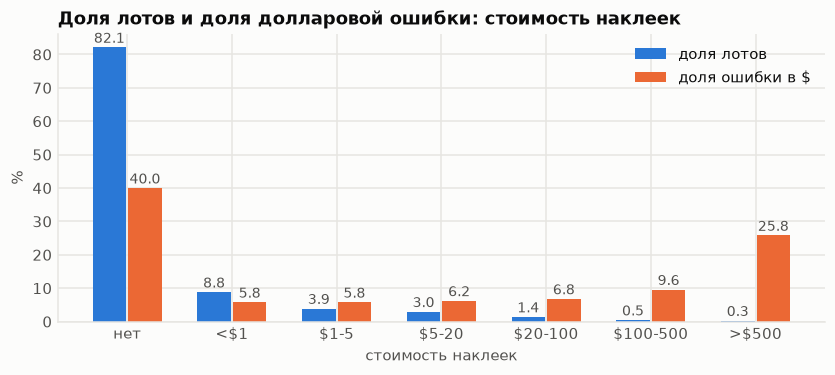

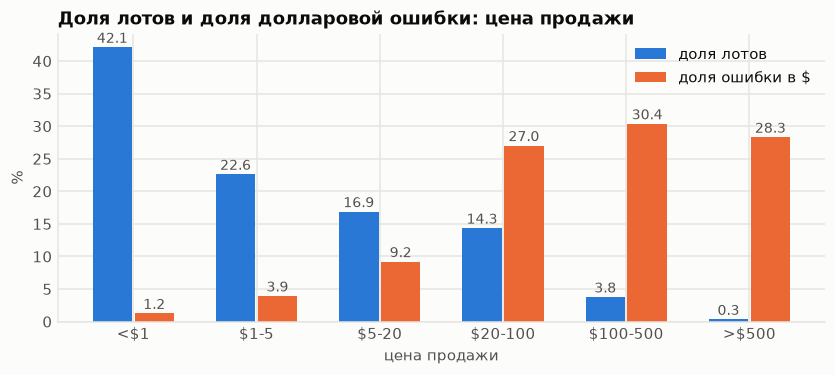

,стоимость наклеек,продаж,"доля продаж, %","доля ошибки в $, %","медианная ошибка, %","средняя ошибка, $"
0,нет,134897,82.13,39.98,5.11,0.67
1,<$1,14495,8.83,5.79,3.63,0.90
2,$1-5,6411,3.90,5.79,4.08,2.04
3,$5-20,4879,2.97,6.25,4.92,2.90
4,$20-100,2303,1.40,6.81,8.01,6.70
5,$100-500,772,0.47,9.58,13.72,28.12
6,>$500,487,0.30,25.81,19.15,120.01


In [2]:
for by in ("sticker_value", "price_band"):
    table = pd.DataFrame(analysis["budget"][by])
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(9, 3.4))
    b1 = ax.bar(x - 0.17, table["share_of_rows"], width=0.32, color=SERIES[0], label="доля лотов")
    b2 = ax.bar(x + 0.17, table["share_of_error"], width=0.32, color=SERIES[1], label="доля ошибки в $")
    bar_labels(ax, b1, "{:.1f}", horizontal=False)
    bar_labels(ax, b2, "{:.1f}", horizontal=False)
    ax.set_xticks(x, [value(str(v)) for v in table[by]])
    ax.set_xlabel(column(by))
    ax.set_ylabel("%")
    ax.set_title(f"Доля лотов и доля долларовой ошибки: {column(by)}")
    ax.legend(loc="upper right")
    plt.show()
russian(pd.DataFrame(analysis["budget"]["sticker_value"]).round(2))

## Незнакомые наборы наклеек

У большинства крафтов в тестовом периоде такого сочетания наклеек в обучении не было.
Модель оценивает их по информации о каждой наклейке отдельно: её цене у CSFloat и
прошлым наценкам за неё. Вопрос в том, сколько точности стоит незнакомое сочетание.

Ответ: почти ничего. До $500 стоимости наклеек ошибка на новых наборах такая же, как на
знакомых. Модель не запоминает конкретные крафты, а понимает, из чего складывается цена.

In [3]:
print(f"У {analysis['novel_sticker_set_share_pct']:.1f}% тестовых крафтов набор наклеек не встречался в обучении")
BANDS = ["<$1", "$1-5", "$5-20", "$20-100", "$100-500", ">$500"]
extrapolation = pd.DataFrame(analysis["extrapolation"])
extrapolation = extrapolation.sort_values("sticker_value", key=lambda s: s.map(BANDS.index))
russian(extrapolation.round(2).reset_index(drop=True))

У 42.4% тестовых крафтов набор наклеек не встречался в обучении


,стоимость наклеек,продаж (новый),продаж (встречался в обучении),"медианная ошибка, % (новый)","медианная ошибка, % (встречался в обучении)"
0,<$1,5234.0,9261.0,3.64,3.62
1,$1-5,2917.0,3494.0,3.97,4.18
2,$5-20,2368.0,2511.0,4.60,5.24
3,$20-100,1200.0,1103.0,7.99,8.06
4,$100-500,416.0,356.0,13.39,14.23
5,>$500,317.0,170.0,21.30,17.92


## Шум рынка

Одинаковые обычные предметы, проданные в один день (то же название, float в пределах
0,005, минимум три продажи), всё равно продаются по разным ценам. Каждую такую продажу
сравним с медианой *других* таких же продаж того же дня. Это оптимистичная нижняя граница
ошибки: такой «прогноз» знает сегодняшние цены, а модель видит только прошлое.

Для предметов дороже $20 модель уже так же точна, как эта граница. Запас остаётся у
дешёвых предметов.

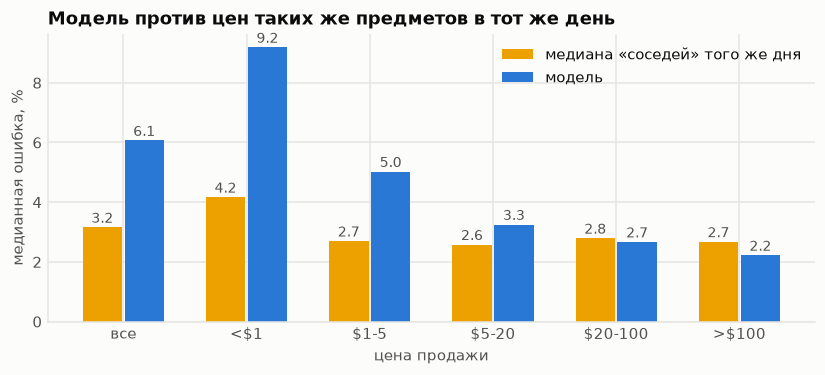

,цена продажи,продаж,"ошибка «соседей по дню», %","ошибка модели, %"
0,все,31374,3.16,6.07
1,<$1,16990,4.17,9.19
2,$1-5,7556,2.70,5.02
3,$5-20,4220,2.58,3.25
4,$20-100,2140,2.79,2.67
5,>$100,468,2.67,2.22


In [4]:
floor = pd.DataFrame(analysis["noise_floor"])
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(floor))
b1 = ax.bar(x - 0.17, floor["floor_mdape_same_day_comparables"], width=0.32, color=SERIES[3], label="медиана «соседей» того же дня")
b2 = ax.bar(x + 0.17, floor["model_mdape"], width=0.32, color=SERIES[0], label="модель")
bar_labels(ax, b1, "{:.1f}", horizontal=False)
bar_labels(ax, b2, "{:.1f}", horizontal=False)
ax.set_xticks(x, [value(str(v)) for v in floor["price_band"]])
ax.set_xlabel("цена продажи")
ax.set_ylabel("медианная ошибка, %")
ax.set_title("Модель против цен таких же предметов в тот же день")
ax.legend(loc="upper right")
plt.show()
russian(floor.round(2))